In [54]:
### simple archictre of multipal agent


from langgraph.graph import StateGraph, START, END, MessagesState
from typing_extensions import Annotated, TypedDict,List, Literal
# anntatition is reducer when i create a data get and store one by one inise the list messgaes
from langgraph.graph.message import add_messages
from langchain.schema import HumanMessage
from langchain_groq import ChatGroq
from langchain_community.tools.tavily_search import TavilySearchResults
from langchain_core.tools import tool
from langgraph.checkpoint.memory import MemorySaver
from langgraph.graph import MessagesState
from langgraph.prebuilt import create_react_agent
from langgraph.prebuilt import ToolNode
from langchain_mcp_adapters.client import MultiServerMCPClient

In [55]:
# class state(TypedDict):
#     message: Annotated[list[dict], add_messages]
    

class State(MessagesState):
    net_agnet: str  # which agnet need to call nect

In [56]:
#create the sample tool

@tool
def search_web(query: str) -> str:
    """Search the web for a query and return the results."""
    # Simulate a web search by returning a fixed string
    sercah=TavilySearchResults(max_results=4)
    results=sercah.invoke(query)
    return str(results)

In [57]:
@tool
def write_the_summery(content: str) -> str:
    """write the summery of the content"""
    # Simulate a web search by returning a fixed string
    summery =f"This is the summery of the content: {content[:500]}..."
    return summery

In [58]:
import os
from dotenv import load_dotenv
load_dotenv()
API_KEY=os.getenv("GROQ_API_KEY")
os.environ["GROQ_API_KEY"]=API_KEY
Travelly=os.getenv("TAVILY_API_KEY")
os.environ["TAVILY_API_KEY"]=Travelly
from langchain_groq import ChatGroq

from langchain.chat_models import init_chat_model
llm = ChatGroq(model="qwen/qwen3-32b", api_key=API_KEY)

In [59]:
def reasarcher_agent(state: State):
    "Reasrcher agent and serach for information"
    start_state = state["message"]
    system_msg=SystemMessage(content="You are a reasrcher agent and you need to find the information for the user")
# measn once i reach about the thing i need to pass to the next agnet
    reasarcher_llm=llm.bind_tools(search_web)
    responce=reasarcher_llm.invoke([system_msg]+ start_state)
    return {
        "message":[responce],
        "next_agnet": "writer"
    }


In [60]:
def writer(state:State):
    "you are the writer based on the research meassage"
    message=state["message"]
    writer_llm=llm.bind_tools(write_the_summery)
    system_msg=SystemMessage(content="You are a writer agent and you need to find the information and review the properly")

    responce=writer_llm.invoke([system_msg]+message)
    return {
        "message": [responce],
        "next_agent": "end"
    }

In [61]:
## tool executer node
def exicute_tool(state: State):
    """exicute the pending message"""
    message=state['message']
    lastmessage=message[-1]
    if hasattr(lastmessage,"too_calls") and lastmessage.tool_calls:
        # create tool node excute
        tool_node=ToolNode([search_web, writer])
        respnse= tool_node.invoke(state)
        return respnse
    return state


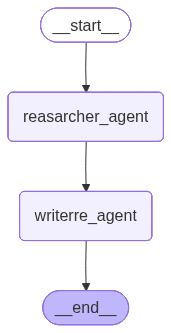

In [73]:
#build the graph
graph=StateGraph(MessagesState)
graph.add_node("reasarcher_agent", reasarcher_agent)
graph.add_node("writerre_agent", writer)


#connect the edgage
graph.set_entry_point("reasarcher_agent")

graph.add_edge("reasarcher_agent", "writerre_agent")
graph.add_edge("writerre_agent", END)
config="che"
build=graph.compile(checkpointer=MemorySaver())
print(build)
build


In [63]:
from langchain.schema import HumanMessage

config = {"configurable": {"thread_id": "thread-1"}}

response = build.invoke(
    {
        "message": "5*6 multipal and tell me new things about AI"
    },
    config=config
)

res = response["message"][-1].content

res

KeyError: 'message'

#### suprevisor multipal agent 

In [64]:
### simple archictre of multipal agent


from langgraph.graph import StateGraph, START, END, MessagesState
from typing_extensions import Annotated, TypedDict,List, Literal, Dict, Any
# anntatition is reducer when i create a data get and store one by one inise the list messgaes
from langgraph.graph.message import add_messages
from langchain.schema import HumanMessage
from langchain_groq import ChatGroq
from langchain_community.tools.tavily_search import TavilySearchResults
from langchain_core.tools import tool
from langgraph.checkpoint.memory import MemorySaver
from langgraph.graph import MessagesState
from langgraph.prebuilt import create_react_agent
from langgraph.prebuilt import ToolNode
from langchain_mcp_adapters.client import MultiServerMCPClient

In [69]:
class SupervisorState(MessagesState):
    """State for the multi-agent system"""
    next_agent: str = ""
    research_data: str = ""
    analysis: str = ""
    final_report: str = ""
    task_complete: bool = False
    current_task: str = ""



In [71]:
from langchain_core.prompts import ChatPromptTemplate
def create_supervisor_chain():
    """Creates the supervisor decision chain"""
    
    supervisor_prompt = ChatPromptTemplate.from_messages([
        ("system", """You are a supervisor managing a team of agents:
        
1. Researcher - Gathers information and data
2. Analyst - Analyzes data and provides insights  
3. Writer - Creates reports and summaries

Based on the current state and conversation, decide which agent should work next.
If the task is complete, respond with 'DONE'.

Current state:
- Has research data: {has_research}
- Has analysis: {has_analysis}
- Has report: {has_report}

Respond with ONLY the agent name (researcher/analyst/writer) or 'DONE'.
"""),
        ("human", "{task}")
    ])
    
    return supervisor_prompt | llm

### chaing the reacheragent to communicate each other decide the which agnet""

 ## supervisor agnet decide all the task

 